# **CIFAR Classifier CNN**
- This project aims at developing a Convolutional Neural Network and benchmarking it on the CIFAR-10 dataset.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import keras
from datasets import load_dataset
from sklearn.model_selection import train_test_split

In [2]:
dataset = load_dataset("uoft-cs/cifar10").with_format("numpy")
X=dataset['train']['img']
y=dataset['train']['label']

README.md:   0%|          | 0.00/5.16k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  120MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 23.9MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/50000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/10000 [00:00<?, ? examples/s]

In [3]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [4]:
X_train=np.array(X_train)
X_test=np.array(X_test)
y_train=np.array(y_train)
y_test=np.array(y_test)

## Data Preprocessing and Label Resolution
- Preprocessing and scaling the images for convolution and keeping a note of what label corresponds to what.

In [5]:
class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer',
               'dog', 'frog', 'horse', 'ship', 'truck']

In [6]:
X_train = X_train / 255.0
X_test = X_test / 255.0

In [7]:
X_train[0]

array([[[0.98431373, 0.97647059, 0.96862745],
        [0.96470588, 0.96078431, 0.96078431],
        [0.96078431, 0.96470588, 0.97254902],
        ...,
        [0.87843137, 0.94509804, 0.97254902],
        [0.81960784, 0.88627451, 0.96470588],
        [0.67843137, 0.72941176, 0.82745098]],

       [[1.        , 1.        , 0.99607843],
        [0.98039216, 0.99607843, 1.        ],
        [0.98039216, 1.        , 1.        ],
        ...,
        [0.52941176, 0.69411765, 0.94901961],
        [0.49803922, 0.65490196, 0.91764706],
        [0.52941176, 0.62352941, 0.80392157]],

       [[0.93333333, 0.96078431, 0.97254902],
        [0.89411765, 0.95686275, 0.97254902],
        [0.90196078, 0.96078431, 0.96862745],
        ...,
        [0.2       , 0.38431373, 0.80392157],
        [0.34509804, 0.50980392, 0.81568627],
        [0.48627451, 0.58431373, 0.76470588]],

       ...,

       [[0.51372549, 0.37647059, 0.40784314],
        [0.41960784, 0.22352941, 0.25882353],
        [0.23921569, 0

- Normalising images for faster convergence

## Model Structure Design

In [63]:
cnn1 = keras.models.Sequential([
    keras.layers.Conv2D(filters=32, kernel_size=3, activation='relu', input_shape=[32, 32, 3]),
    keras.layers.MaxPool2D(pool_size=2, strides=2),
    keras.layers.Conv2D(filters=32, kernel_size=3, activation='relu'),
    keras.layers.MaxPool2D(pool_size=2, strides=2),

    keras.layers.Flatten(),
    keras.layers.Dense(units=128, activation='relu'),
    keras.layers.Dense(units=10, activation='softmax')
], name="cnn1")
cnn1.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

cnn2 = keras.models.Sequential([
    keras.layers.Conv2D(filters=32, kernel_size=3, activation='relu', input_shape=[32, 32, 3]),
    keras.layers.MaxPool2D(pool_size=2, strides=2),
    keras.layers.Conv2D(filters=64, kernel_size=3, activation='relu'),
    keras.layers.MaxPool2D(pool_size=2, strides=2),

    keras.layers.Flatten(),
    keras.layers.Dense(units=128, activation='relu'),
    keras.layers.Dropout(0.5),
    keras.layers.Dense(units=64, activation='relu'),
    keras.layers.Dense(units=10, activation='softmax')
], name="cnn2")
cnn2.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

cnn3 = keras.models.Sequential([
    keras.layers.Conv2D(filters=32, kernel_size=3, activation='relu', input_shape=[32, 32, 3]),
    keras.layers.MaxPool2D(pool_size=2, strides=2),
    keras.layers.Conv2D(filters=64, kernel_size=3, activation='relu'),
    keras.layers.MaxPool2D(pool_size=2, strides=2),
    keras.layers.Conv2D(filters=32, kernel_size=3, activation='relu'),
    keras.layers.MaxPool2D(pool_size=2, strides=2),

    keras.layers.Flatten(),
    keras.layers.Dense(units=128, activation='relu'),
    keras.layers.Dropout(0.5),
    keras.layers.Dense(units=64, activation='relu'),
    keras.layers.Dense(units=10, activation='softmax')
], name="cnn3")
cnn3.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

cnn4 = keras.models.Sequential([
    keras.layers.Conv2D(filters=32, kernel_size=3, padding='same', activation='relu', input_shape=[32, 32, 3]),
    keras.layers.Conv2D(filters=64, kernel_size=3, padding='same', activation='relu'),
    keras.layers.MaxPool2D(pool_size=2, strides=2),
    keras.layers.Conv2D(filters=64, kernel_size=3, padding='same', activation='relu'),
    keras.layers.Conv2D(filters=64, kernel_size=3, padding='same', activation='relu'),
    keras.layers.MaxPool2D(pool_size=2, strides=2),
    keras.layers.Conv2D(filters=64, kernel_size=3, padding='same', activation='relu'),
    keras.layers.Conv2D(filters=64, kernel_size=3, padding='same', activation='relu'),
    keras.layers.MaxPool2D(pool_size=2, strides=2),

    keras.layers.Flatten(),
    keras.layers.Dense(units=128, activation='relu'),
    keras.layers.Dropout(0.5),
    keras.layers.Dense(units=64, activation='relu'),
    keras.layers.Dropout(0.25),
    keras.layers.Dense(units=32, activation='relu'),
    keras.layers.Dense(units=10, activation='softmax')
], name="cnn4")
cnn4.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

cnn5 = keras.models.Sequential([
    keras.layers.Conv2D(filters=32, kernel_size=3, padding='same', activation='relu', input_shape=[32, 32, 3]),
    keras.layers.Conv2D(filters=64, kernel_size=3, padding='same', activation='relu'),
    keras.layers.MaxPool2D(pool_size=2, strides=2),
    keras.layers.Dropout(0.2),
    keras.layers.Conv2D(filters=64, kernel_size=3, padding='same', activation='relu'),
    keras.layers.Conv2D(filters=64, kernel_size=3, padding='same', activation='relu'),
    keras.layers.MaxPool2D(pool_size=2, strides=2),
    keras.layers.Dropout(0.3),
    keras.layers.Conv2D(filters=64, kernel_size=3, padding='same', activation='relu'),
    keras.layers.Conv2D(filters=64, kernel_size=3, padding='same', activation='relu'),
    keras.layers.MaxPool2D(pool_size=2, strides=2),
    keras.layers.Dropout(0.4),

    keras.layers.Flatten(),
    keras.layers.Dense(units=128, activation='relu'),
    keras.layers.Dropout(0.5),
    keras.layers.Dense(units=64, activation='relu'),
    keras.layers.Dropout(0.25),
    keras.layers.Dense(units=32, activation='relu'),
    keras.layers.Dense(units=10, activation='softmax')
], name="cnn5")

cnn5.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
cnn6 = keras.models.Sequential([
    keras.layers.Conv2D(filters=32, kernel_size=3, padding='same', activation='relu', input_shape=[32, 32, 3]),
    keras.layers.Conv2D(filters=64, kernel_size=3, padding='same', activation='relu'),
    keras.layers.MaxPool2D(pool_size=2, strides=2),
    keras.layers.Dropout(0.2),
    keras.layers.Conv2D(filters=64, kernel_size=3, padding='same', activation='relu'),
    keras.layers.Conv2D(filters=64, kernel_size=3, padding='same', activation='relu'),
    keras.layers.MaxPool2D(pool_size=2, strides=2),
    keras.layers.Dropout(0.3),
    keras.layers.Conv2D(filters=64, kernel_size=3, padding='same', activation='relu'),
    keras.layers.Conv2D(filters=64, kernel_size=3, padding='same', activation='relu'),
    keras.layers.MaxPool2D(pool_size=2, strides=2),
    keras.layers.Dropout(0.4),

    keras.layers.Flatten(),
    keras.layers.Dense(units=128, activation='relu'),
    keras.layers.Dropout(0.5),
    keras.layers.Dense(units=32, activation='relu'),
    keras.layers.Dense(units=10, activation='softmax')
], name="cnn6")
cnn6.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
cnn7 = keras.models.Sequential([
    keras.layers.Conv2D(filters=32, kernel_size=3, padding='same', activation='relu', input_shape=[32, 32, 3]),
    keras.layers.Conv2D(filters=64, kernel_size=3, padding='same', activation='relu'),
    keras.layers.MaxPool2D(pool_size=2, strides=2),
    keras.layers.Dropout(0.2),
    keras.layers.Conv2D(filters=64, kernel_size=3, padding='same', activation='relu'),
    keras.layers.Conv2D(filters=64, kernel_size=3, padding='same', activation='relu'),
    keras.layers.MaxPool2D(pool_size=2, strides=2),
    keras.layers.Dropout(0.3),
    keras.layers.Conv2D(filters=64, kernel_size=3, padding='same', activation='relu'),
    keras.layers.Conv2D(filters=64, kernel_size=3, padding='same', activation='relu'),
    keras.layers.MaxPool2D(pool_size=2, strides=2),
    keras.layers.Dropout(0.4),

    keras.layers.Flatten(),
    keras.layers.Dense(units=128, activation='relu'),
    keras.layers.Dropout(0.5),
    keras.layers.Dense(units=10, activation='softmax')
], name="cnn7")
cnn7.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
cnn8 = keras.models.Sequential([
    keras.layers.Conv2D(filters=32, kernel_size=3, padding='same', activation='relu', input_shape=[32, 32, 3]),
    keras.layers.Conv2D(filters=64, kernel_size=3, padding='same', activation='relu'),
    keras.layers.MaxPool2D(pool_size=2, strides=2),
    keras.layers.Dropout(0.2),
    keras.layers.Conv2D(filters=64, kernel_size=3, padding='same', activation='relu'),
    keras.layers.Conv2D(filters=64, kernel_size=3, padding='same', activation='relu'),
    keras.layers.MaxPool2D(pool_size=2, strides=2),
    keras.layers.Dropout(0.3),
    keras.layers.Conv2D(filters=128, kernel_size=3, padding='same', activation='relu'),
    keras.layers.Conv2D(filters=128, kernel_size=3, padding='same', activation='relu'),
    keras.layers.MaxPool2D(pool_size=2, strides=2),
    keras.layers.Dropout(0.4),

    keras.layers.GlobalAveragePooling2D(),
    keras.layers.Dropout(0.5),
    keras.layers.Dense(units=10, activation='softmax')
], name="cnn8")
cnn8.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
cnn9 = keras.models.Sequential([
    keras.layers.Conv2D(filters=32, kernel_size=3, padding='same', activation='relu', input_shape=[32, 32, 3]),
    keras.layers.Conv2D(filters=64, kernel_size=3, padding='same', activation='relu'),
    keras.layers.MaxPool2D(pool_size=2, strides=2),
    keras.layers.Dropout(0.2),
    keras.layers.Conv2D(filters=64, kernel_size=3, padding='same', activation='relu'),
    keras.layers.Conv2D(filters=64, kernel_size=3, padding='same', activation='relu'),
    keras.layers.MaxPool2D(pool_size=2, strides=2),
    keras.layers.Dropout(0.3),
    keras.layers.Conv2D(filters=128, kernel_size=3, padding='same', activation='relu'),
    keras.layers.Conv2D(filters=128, kernel_size=3, padding='same', activation='relu'),
    keras.layers.MaxPool2D(pool_size=2, strides=2),
    keras.layers.Dropout(0.4),

    keras.layers.GlobalAveragePooling2D(),
    keras.layers.Dropout(0.1),
    keras.layers.Dense(units=10, activation='softmax')
], name="cnn9")
cnn9.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

cnn10 = keras.models.Sequential([

    keras.layers.Conv2D(filters=32, kernel_size=3, padding='same', activation='relu', input_shape=[32, 32, 3]),
    keras.layers.BatchNormalization(),
    keras.layers.Conv2D(filters=64, kernel_size=3, padding='same', activation='relu'),
    keras.layers.BatchNormalization(),
    keras.layers.MaxPool2D(pool_size=2, strides=2),
    keras.layers.Dropout(0.2),

    keras.layers.Conv2D(filters=64, kernel_size=3, padding='same', activation='relu'),
    keras.layers.BatchNormalization(),
    keras.layers.Conv2D(filters=64, kernel_size=3, padding='same', activation='relu'),
    keras.layers.BatchNormalization(),
    keras.layers.MaxPool2D(pool_size=2, strides=2),
    keras.layers.Dropout(0.3),

    keras.layers.Conv2D(filters=128, kernel_size=3, padding='same', activation='relu'),
    keras.layers.BatchNormalization(),
    keras.layers.Conv2D(filters=128, kernel_size=3, padding='same', activation='relu'),
    keras.layers.BatchNormalization(),
    keras.layers.MaxPool2D(pool_size=2, strides=2),
    keras.layers.Dropout(0.4),

    keras.layers.GlobalAveragePooling2D(),
    keras.layers.Dropout(0.1),
    keras.layers.Dense(units=10, activation='softmax')
], name="cnn10")
cnn10.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

cnn11 = keras.models.Sequential([

    keras.layers.Conv2D(filters=64, kernel_size=3, padding='same', activation='relu', input_shape=[32, 32, 3]),
    keras.layers.BatchNormalization(),
    keras.layers.Conv2D(filters=64, kernel_size=3, padding='same', activation='relu'),
    keras.layers.BatchNormalization(),
    keras.layers.MaxPool2D(pool_size=2, strides=2),
    keras.layers.Dropout(0.2),

    keras.layers.Conv2D(filters=128, kernel_size=3, padding='same', activation='relu'),
    keras.layers.BatchNormalization(),
    keras.layers.Conv2D(filters=128, kernel_size=3, padding='same', activation='relu'),
    keras.layers.BatchNormalization(),
    keras.layers.MaxPool2D(pool_size=2, strides=2),
    keras.layers.Dropout(0.3),

    keras.layers.Conv2D(filters=256, kernel_size=3, padding='same', activation='relu'),
    keras.layers.BatchNormalization(),
    keras.layers.Conv2D(filters=256, kernel_size=3, padding='same', activation='relu'),
    keras.layers.BatchNormalization(),
    keras.layers.Dropout(0.4),

    keras.layers.GlobalAveragePooling2D(),
    keras.layers.Dropout(0.1),
    keras.layers.Dense(units=10, activation='softmax')
], name="cnn11")
cnn11.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])


cnn12 = keras.models.Sequential([
    keras.Input(shape=[32, 32, 3]),
    keras.layers.RandomFlip("horizontal"),
    keras.layers.RandomTranslation(0.1, 0.1),
    keras.layers.RandomZoom(0.1),

    keras.layers.Conv2D(filters=64, kernel_size=3, padding='same', activation='relu'),
    keras.layers.BatchNormalization(),
    keras.layers.Conv2D(filters=64, kernel_size=3, padding='same', activation='relu'),
    keras.layers.BatchNormalization(),
    keras.layers.MaxPool2D(pool_size=2, strides=2),
    keras.layers.Dropout(0.2),

    keras.layers.Conv2D(filters=128, kernel_size=3, padding='same', activation='relu'),
    keras.layers.BatchNormalization(),
    keras.layers.Conv2D(filters=128, kernel_size=3, padding='same', activation='relu'),
    keras.layers.BatchNormalization(),
    keras.layers.MaxPool2D(pool_size=2, strides=2),
    keras.layers.Dropout(0.3),

    keras.layers.Conv2D(filters=256, kernel_size=3, padding='same', activation='relu'),
    keras.layers.BatchNormalization(),
    keras.layers.Conv2D(filters=256, kernel_size=3, padding='same', activation='relu'),
    keras.layers.BatchNormalization(),
    keras.layers.GlobalAveragePooling2D(),
    keras.layers.Dropout(0.3),

    keras.layers.Dense(units=10, activation='softmax')
], name="cnn12")
cnn12.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])






/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
cnn1.fit(X_train, y_train, epochs=30, validation_data=(X_test, y_test))
cnn2.fit(X_train, y_train, epochs=30, validation_data=(X_test, y_test))
cnn3.fit(X_train, y_train, epochs=30, validation_data=(X_test, y_test))
cnn4.fit(X_train, y_train, epochs=30, validation_data=(X_test, y_test))
cnn5.fit(X_train, y_train, epochs=30, validation_data=(X_test, y_test))
cnn6.fit(X_train, y_train, epochs=30, validation_data=(X_test, y_test))
cnn7.fit(X_train, y_train, epochs=30, validation_data=(X_test, y_test))
cnn8.fit(X_train, y_train, epochs=30, validation_data=(X_test, y_test))
cnn9.fit(X_train, y_train, epochs=30, validation_data=(X_test, y_test))
cnn10.fit(X_train, y_train, epochs=30, validation_data=(X_test, y_test))
cnn11.fit(X_train, y_train, epochs=30, validation_data=(X_test, y_test))
cnn12.fit(X_train, y_train, epochs=30, validation_data=(X_test, y_test))

Epoch 1/30
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.4482 - loss: 1.5302 - val_accuracy: 0.5379 - val_loss: 1.2928
Epoch 2/30
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.5754 - loss: 1.1950 - val_accuracy: 0.5851 - val_loss: 1.1696
Epoch 3/30
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.6260 - loss: 1.0626 - val_accuracy: 0.6308 - val_loss: 1.0557
Epoch 4/30
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - accuracy: 0.6603 - loss: 0.9688 - val_accuracy: 0.6488 - val_loss: 1.0100
Epoch 5/30
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.6834 - loss: 0.8962 - val_accuracy: 0.6457 - val_loss: 1.0125
Epoch 6/30
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.7094 - loss: 0.8281 - val_accuracy: 0.6638 - val_loss: 0.9915
Epoch 7/30
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.7301 - loss: 0.7738 - val_accuracy: 0.6542 - val_loss: 1.0024
Epoch 8/30
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.7456 - loss: 0.7198 - 

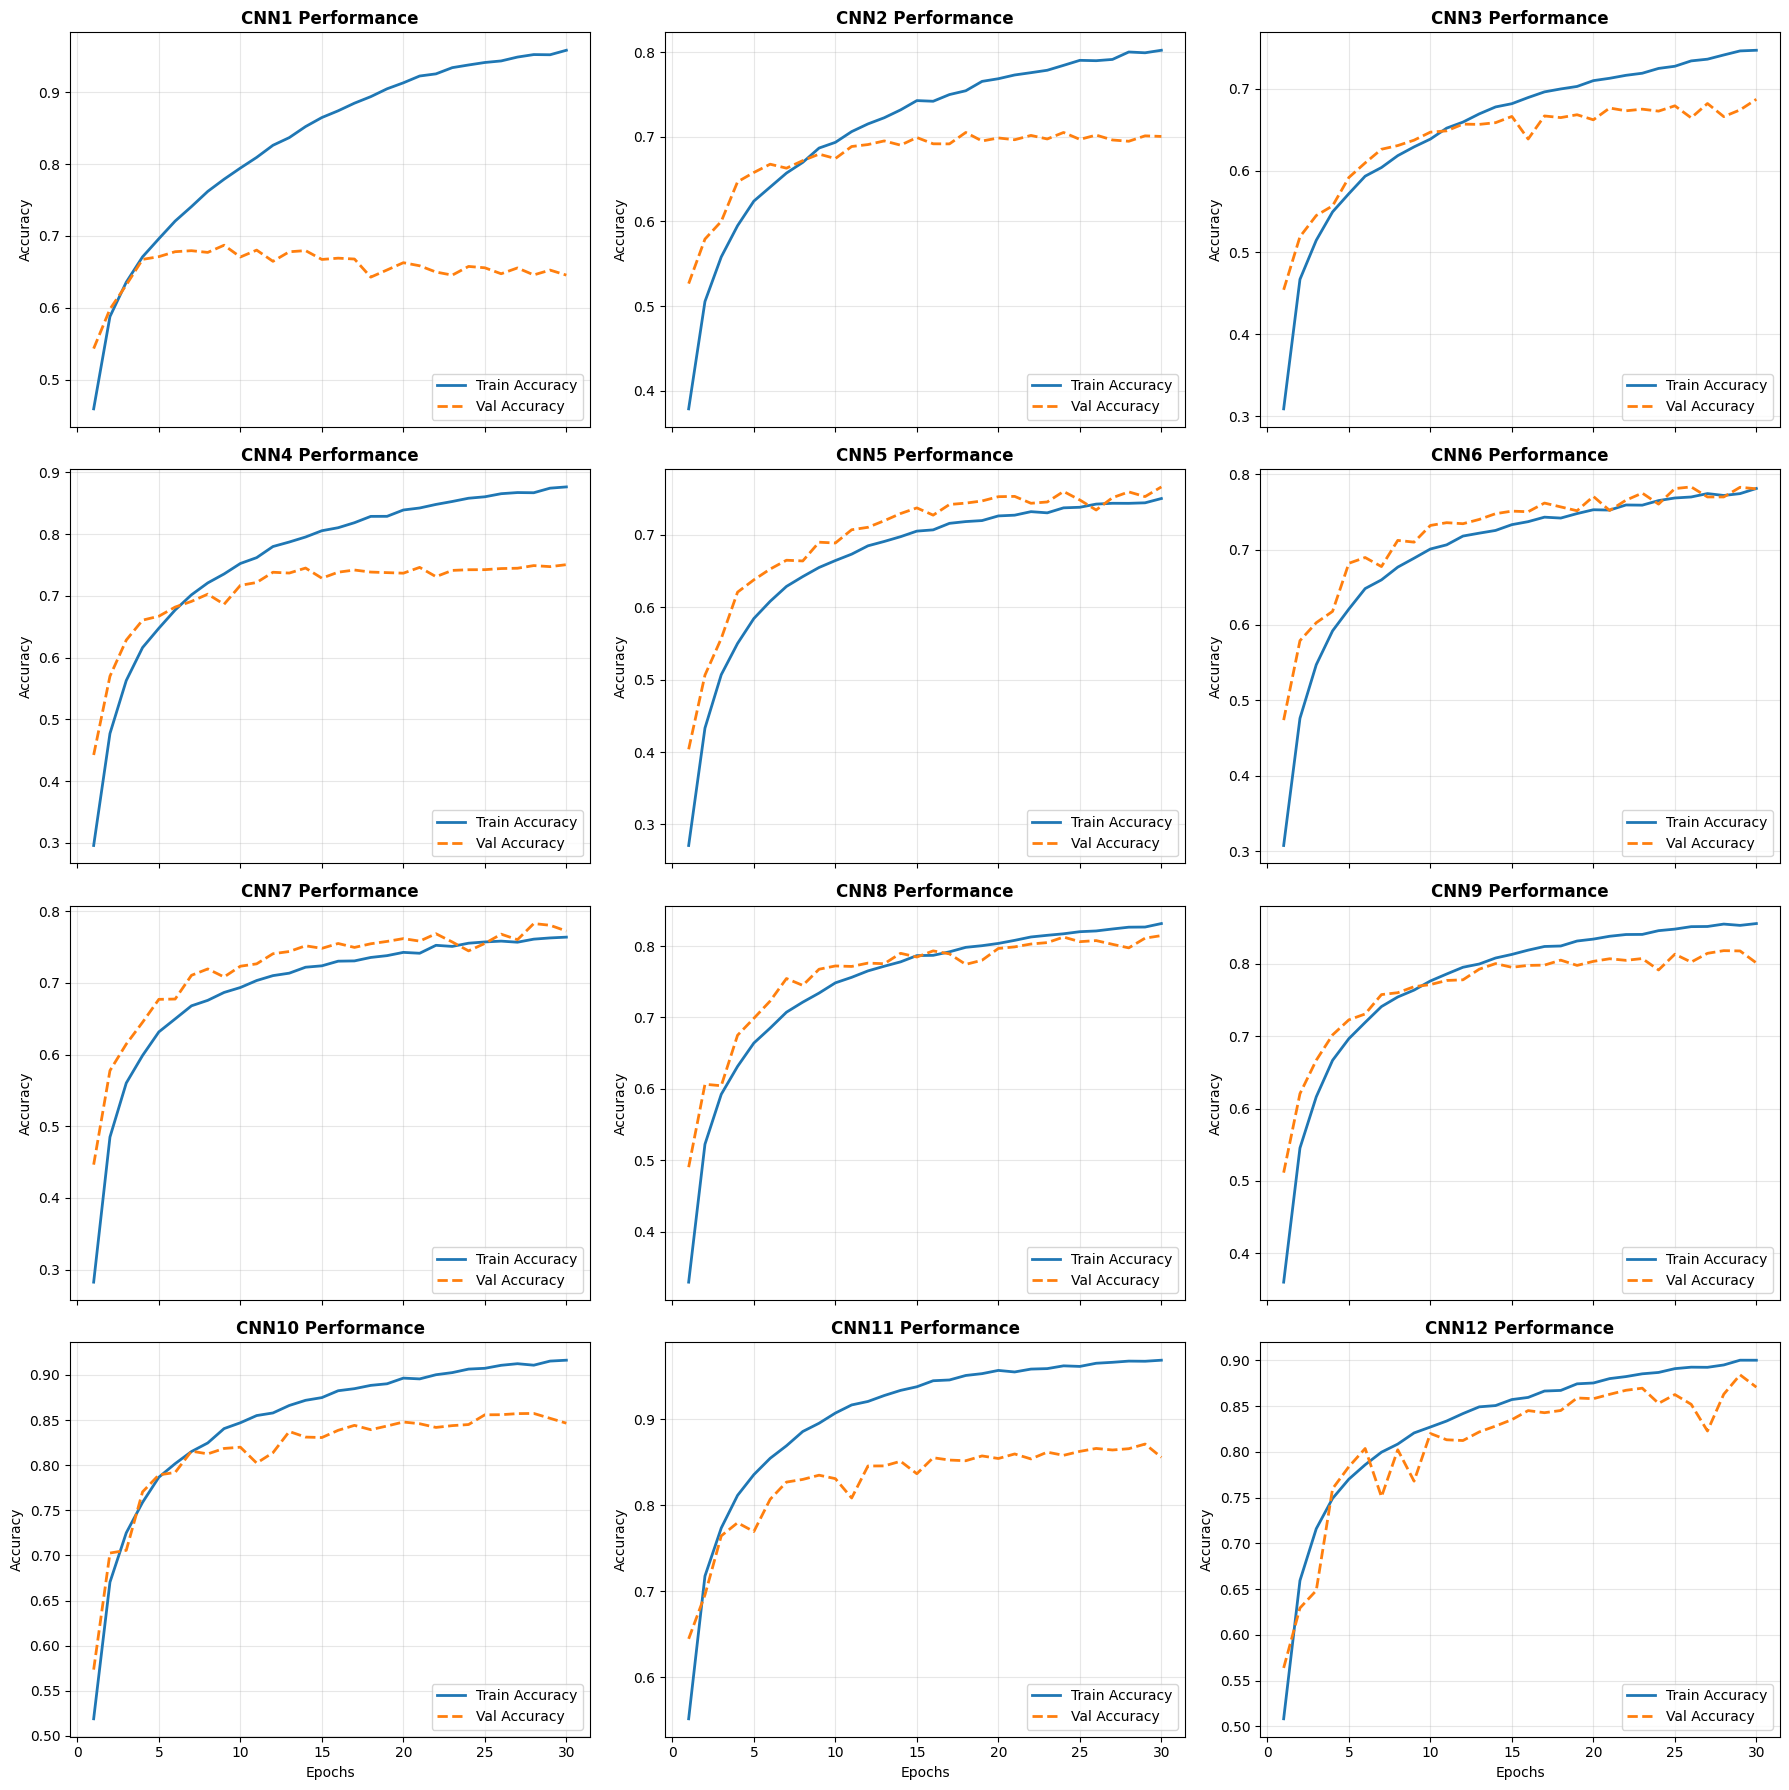

In [57]:
import gc
import math
import matplotlib.pyplot as plt

models = [cnn1, cnn2, cnn3, cnn4, cnn5, cnn6, cnn7,cnn8,cnn9,cnn10,cnn11,cnn12]
histories = {}
gc.collect()

num_models = len(models)
rows = math.ceil(math.sqrt(num_models))
cols = math.ceil(num_models / rows)

fig, axes = plt.subplots(rows, cols, figsize=(6 * cols, 4.5 * rows), sharex=True, squeeze=False)
axes = axes.flatten()

for i, model in enumerate(models):
    name = model.name
    ax = axes[i]

    epochs_range = range(1, len(model.history.history['accuracy']) + 1)

    ax.plot(epochs_range, model.history.history['accuracy'], label='Train Accuracy', color='tab:blue', linewidth=2)
    ax.plot(epochs_range, model.history.history['val_accuracy'], label='Val Accuracy', color='tab:orange', linestyle='--', linewidth=2)

    ax.set_title(f'{name.upper()} Performance', fontsize=12, fontweight='bold')
    ax.set_ylabel('Accuracy')
    ax.grid(True, alpha=0.3)
    ax.legend(loc='lower right')

    if i >= num_models - cols:
        ax.set_xlabel('Epochs')
        ax.tick_params(labelbottom=True)

for j in range(num_models, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()


In [62]:

models = [cnn1, cnn2, cnn3, cnn4, cnn5, cnn6, cnn7, cnn8, cnn10,cnn11,cnn12]

results = []
for model in models:
    if hasattr(model, 'history') and model.history is not None:
        val_acc = model.history.history.get('val_accuracy', [])
        if val_acc:
            best_idx = int(np.argmax(val_acc))
            best_acc = val_acc[best_idx]
            best_epoch = best_idx + 1
            results.append((model.name, best_acc, best_epoch, len(val_acc)))

results.sort(key=lambda x: x[1], reverse=True)

print(f"{'Model':<10} | {'Best Val Acc':<14} | {'Best Epoch':<12} | {'Total Epochs'}")
print("-" * 55)
for name, acc, epoch, total in results:
    print(f"{name:<10} | {acc*100:>12.2f}% | {epoch:>10}   | {total:>12}")


Model      | Best Val Acc   | Best Epoch   | Total Epochs
-------------------------------------------------------
cnn12      |        88.41% |         29   |           30
cnn11      |        87.10% |         29   |           30
cnn10      |        85.74% |         28   |           30
cnn8       |        81.46% |         30   |           30
cnn6       |        78.30% |         26   |           30
cnn7       |        78.28% |         28   |           30
cnn5       |        76.64% |         30   |           30
cnn4       |        75.06% |         30   |           30
cnn2       |        70.52% |         18   |           30
cnn3       |        68.73% |         30   |           30
cnn1       |        68.71% |          9   |           30


# Observation and Results
* **CNN1 — Baseline Architecture (`68.71%` at Epoch 9):** Uses two convolutional blocks (`32 → 32` filters) with `valid` padding, `MaxPool2D`, `Flatten`, and a `Dense(128) → Dense(10)` head. Establishes the initial CIFAR-10 benchmark without regularization, peaking early at epoch 9 before overfitting.
* **CNN2 — Filter Expansion & Head Regularization (`70.52%` at Epoch 18):** Expands the second block (`32 → 64` filters) and introduces a `Dense(128) → Dropout(0.5) → Dense(64) → Dense(10)` classifier. Delays overfitting to epoch 18 and improves validation accuracy by `+1.81%`.
* **CNN3 — Deeper Bottleneck Exploration (`68.73%` at Epoch 30):** Adds a third convolutional block (`32 → 64 → 32` filters) with `valid` padding and three `MaxPool2D` layers. Compresses feature maps down to `2×2` before flattening, losing spatial detail and dropping accuracy back to baseline levels.
* **CNN4 — VGG-Style Stacked Convolutions (`75.06%` at Epoch 30):** Switches to `padding='same'` across three double-convolution blocks (`(32, 64) → (64, 64) → (64, 64)`) with a three-layer dense head (`128 → 64 → 32`). Preserves border pixels and builds deeper feature hierarchies, delivering a `+6.33%` jump.
* **CNN5 — Progressive Spatial Regularization (`76.64%` at Epoch 30):** Keeps the `cnn4` VGG-style backbone and adds progressive spatial `Dropout(0.2 → 0.3 → 0.4)` after each pooling block. Curbs overfitting in the deeper backbone and lifts validation accuracy by `+1.58%`.
* **CNN6 — Classifier Pruning, Step 1 (`78.30%` at Epoch 26):** Retains the `cnn5` convolutional backbone and trims the dense head to `Dense(128) → Dropout(0.5) → Dense(32) → Dense(10)`. Removes the intermediate `64`-unit dense layer to cut parameter bloat, gaining `+1.66%`.
* **CNN7 — Minimal Dense Classifier, Step 2 (`78.28%` at Epoch 28):** Simplifies the classifier head down to a single `Dense(128) → Dropout(0.5) → Dense(10)` layer while keeping the same convolutional backbone. Matches `cnn6` (`78.28%` vs. `78.30%`) with fewer parameters.
* **CNN8 — Global Average Pooling & Wider Block 3 (`81.46%` at Epoch 30):** Expands the third block to `(128, 128)` filters and replaces `Flatten` + `Dense(128)` with `GlobalAveragePooling2D() → Dropout(0.5) → Dense(10)`. Breaks past the 80% mark (`+3.18%` jump) while slashing classifier parameters.
* **CNN9 — Classifier Dropout Calibration (Not Evaluated):** Keeps the `cnn8` backbone (`(32, 64) → (64, 64) → (128, 128)`) while lowering post-GAP dropout from `0.5` to `0.1` to prevent signal starvation before the final softmax layer.
* **CNN10 — Batch Normalization Stabilization (`85.74%` at Epoch 28):** Adds `BatchNormalization()` after every `Conv2D` layer across the `(32, 64) → (64, 64) → (128, 128)` backbone with `GlobalAveragePooling2D() → Dropout(0.1) → Dense(10)`. Stabilizes activations and drives a `+4.28%` surge over `cnn8`.
* **CNN11 — Full Filter Scaling & Higher Spatial Resolution (`87.10%` at Epoch 29):** Doubles filter capacity across all blocks (`(64, 64) → (128, 128) → (256, 256)`) with `BatchNormalization` and removes the final `MaxPool2D` so `GlobalAveragePooling2D()` averages over an `8×8` spatial grid. Reaches `87.10%` validation accuracy.
* **CNN12 — On-the-Fly Data Augmentation (`88.41%` at Epoch 29):** Prepends `RandomFlip("horizontal")`, `RandomTranslation(0.1, 0.1)`, and `RandomZoom(0.1)` to the `cnn11` backbone (`64 → 128 → 256`) and consolidates trailing dropout into `Dropout(0.3)`. Prevents pixel memorization and achieves the highest score at `88.41%`.
